# Libraries

In [1]:
from MultiLayerNet import *

CUDA not available, running on CPU


# Tunning Parameters

In [11]:
steps=5000
lr=1e-3
layers = np.array([1,30,30,30,30,1]) #5 hidden layers
# To generate new data:
min=-1
max=1
total_points=500
#Nu: Number of training points (2 as we onlt have 2 boundaries), # Nf: Number of collocation points (Evaluate PDE)
Nu=2
Nf=250

# Problem Setup

**Laplace Operator($\Delta$)**

$$\Delta u=u_{xx}+u_{yy} = \frac{\partial^2 u}{\partial x^2}+\frac{\partial^2 u}{\partial y^2}$$

**Harmonic Functions**

$$\Delta u =0$$

They are smooth

You need boundary conditions: you need the rate or the value.

You have to solve all points at the same time.

**Poisson equation**

$$\Delta u =f(x)$$

Example: Candle in a room

### Problem

$$-\Delta u=\pi^2sin(\pi x)$$

### Boundary Conditions:

$$u(-1)=0, u(1) =0$$

### Exact solution:

$$u(x)=sin(\pi x)$$

### PDE:
$$-\Delta u=\pi^2sin(\pi x)$$
$$u_{xx}=-\pi^2sin(\pi x)$$
$$\frac{\partial^2u}{\partial x^2}=-\pi^2sin(\pi x)$$

So the residual will be:

$$0=\frac{\partial^2u}{\partial x^2}+\pi^2sin(\pi x)$$

Note: Remeber that our neural network $NN(x)\approx u(x)$ so:

$$\frac{\partial^2NN}{\partial x^2}\approx\frac{\partial^2u}{\partial x^2}$$

$$f=\frac{\partial^2NN}{\partial x^2}+\pi^2sin(\pi x)\rightarrow 0$$


**Initial Conditions (Dirichlet BC)**
$$u(-1)=0$$

$$u(1)=0$$

Set a function to describe our boundary conditions:

$$f_{BC}(x)=1-|x|$$

Note: $f_{BC}$ is not the answer to our PDE, but it helps us describe the boundary condition (Generate data).

## Functions

In [5]:
def f_BC(x):
  return 1-torch.abs(x)
def f_real(x):
  return torch.sin(np.pi*x)
def PDE(x):
  return -1*(np.pi**2)*torch.sin(np.pi*x)


In [6]:
def mygrad(y, x):
    dydx = grad(y, x, torch.ones(x.size()[0], 1, device=dev),
                create_graph=True, retain_graph=True)[0]
    return dydx

### Neural Network

# Generate data

In [7]:
# get the analytical solution over the full domain
x = torch.linspace(min,max,total_points).view(-1,1) #prepare to NN
y = f_real(x)
print(x.shape, y.shape)


torch.Size([500, 1]) torch.Size([500, 1])


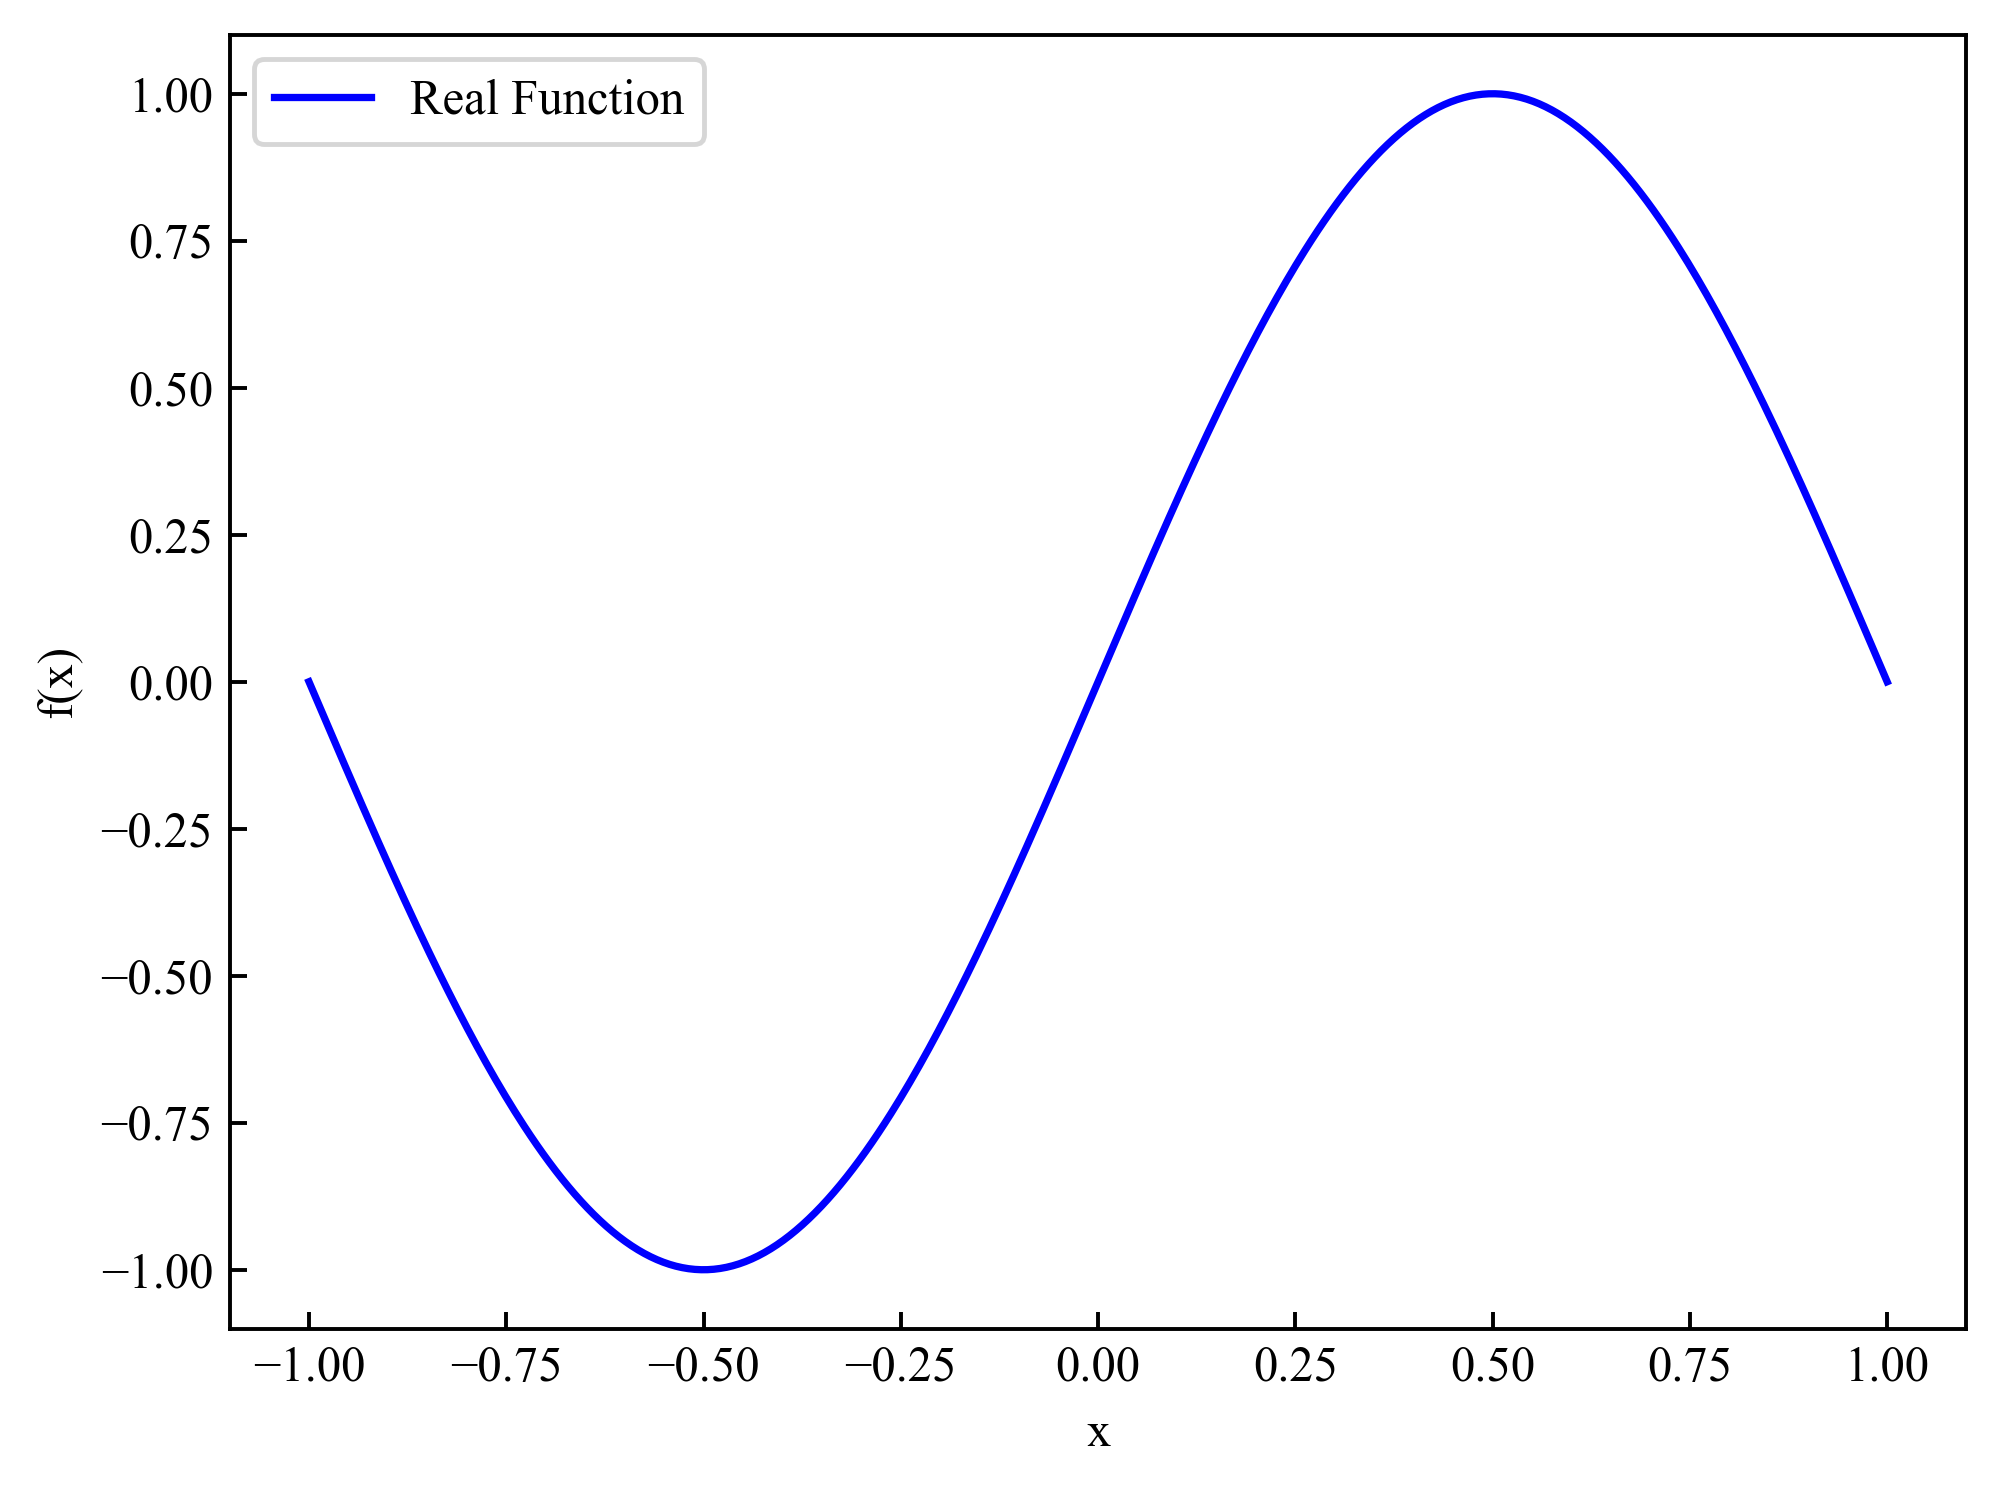

In [8]:
fig, ax1 = plt.subplots()
ax1.plot(x.detach().numpy(),y.detach().numpy(),color='blue',label='Real Function')
#ax1.plot(x_train.detach().numpy(),yh.detach().numpy(),color='red',label='Pred_Train')
ax1.set_xlabel('x',color='black')
ax1.set_ylabel('f(x)',color='black')
ax1.tick_params(axis='y', color='black')
ax1.legend(loc = 'upper left')

In [16]:
#def get_training_data(x):
#Nu: Number of training point, # Nf: Number of colloction points
# Set Boundary conditions x=min & x= max
BC_1=x[0,:]
BC_2=x[-1,:]
# Total Tpaining points BC1+BC2
x_BC=torch.vstack([BC_1,BC_2])
#Select Nf points
# Latin Hypercube sampling for collocation points 
x_PDE = BC_1 + (BC_2-BC_1)*lhs(1,Nf)
x_PDE = torch.vstack((x_PDE,x_BC)) 

In [17]:
y_BC=f_BC(x_BC).to(dev)

tensor([[0.],
        [0.]])


# Train Neural Network

In [18]:
#Store tensors to GPU
x_PDE=x_PDE.float().to(dev)
x_BC=x_BC.to(dev)
#Create Model
model = MultiLayerNet(layers, init=True)
model.to(dev)
optimizer = torch.optim.Adam(model.parameters(),lr=lr,amsgrad=False)
start_time = time.time()

Constructor: Init Network!


In [ ]:
for i in range(steps):
    yh = model(x_PDE)
    
    loss = model.loss(x_BC,y_BC,x_PDE)# use mean squared error
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if i%(steps/10)==0:
      print(loss)

tensor(47.8950, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0152, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0030, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0016, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0008, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0004, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0002, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0003, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0032, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0005, device='cuda:0', grad_fn=<AddBackward0>)


### Plots

In [ ]:
# Function
yh=model(x.to(device))
y=f_real(x)
#Error
print(model.lossBC(x.to(device),f_real(x).to(device)))

tensor(8.2365e-06, device='cuda:0', grad_fn=<MseLossBackward0>)


In [ ]:
# Derivative
g=x.to(device)
g=g.clone()
g.requires_grad=True #Enable differentiation
f=model(g)
f_x=autograd.grad(f,g,torch.ones([g.shape[0],1]).to(device),retain_graph=True, create_graph=True)[0]

In [ ]:
# Detach from GPU
y_plot=y.detach().numpy()
yh_plot=yh.detach().cpu().numpy()
f_x_plot=f_x.detach().cpu().numpy()

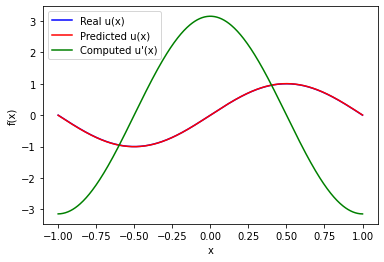

In [ ]:
# Plot
fig, ax1 = plt.subplots()
ax1.plot(x,y_plot,color='blue',label='Real u(x)')
ax1.plot(x,yh_plot,color='red',label='Predicted u(x)')
ax1.plot(x,f_x_plot,color='green',label='Computed u\'(x)')
ax1.set_xlabel('x',color='black')
ax1.set_ylabel('f(x)',color='black')
ax1.tick_params(axis='y', color='black')
ax1.legend(loc = 'upper left')